<function matplotlib.pyplot.show(close=None, block=None)>

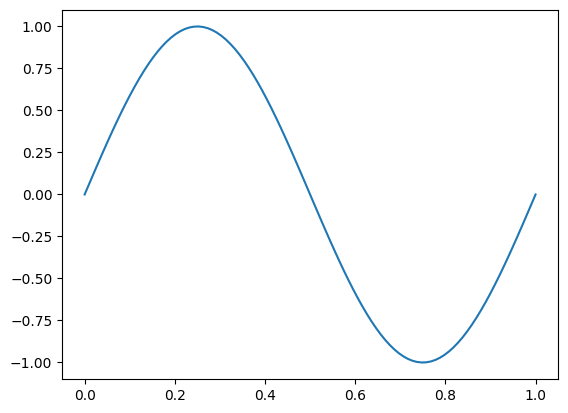

In [1]:
import numpy as np
import matplotlib.pyplot as plt
N = 100
x = np.linspace(0, 1, N)
x = x.reshape(-1,1)
y = np.sin(2*np.pi*x)
plt.plot(x,y)
plt.show

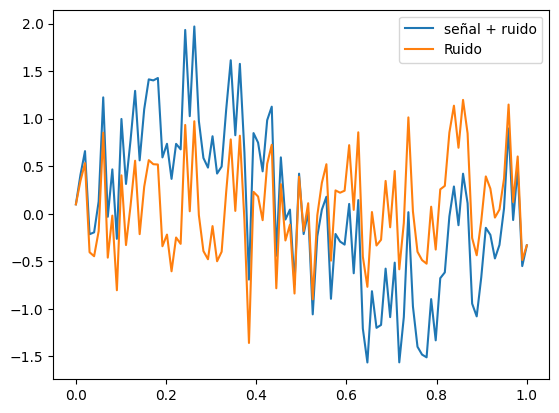

In [4]:
def snr_db(y_t, snr_db):
  Ps = np.mean(y_t**2)
  pn = Ps / (10 ** (snr_db / 10))
  n_o = np.random.normal(0, np.sqrt(pn), size=y_t.shape)
  return y_t + n_o, n_o, pn

t, n_o, sigma2 = snr_db(y, 3)
plt.plot(x, t, label="señal + ruido")
plt.plot(x, n_o, label="Ruido")
plt.legend()
plt.show()

In [12]:
def Phi_f (x,Q):
  X = np.asanyarray(x.reshape(-1,1))
  return np.column_stack([X**q for q in range(Q)])
phi = Phi_f(x,10)

def solver(Phi,y,l):
  inv = np.linalg.pinv(Phi.T@phi + l*np.eye(phi.shape[1]))
  ninv= phi.T@y
  return inv@ninv

W = solver (phi,x,0)

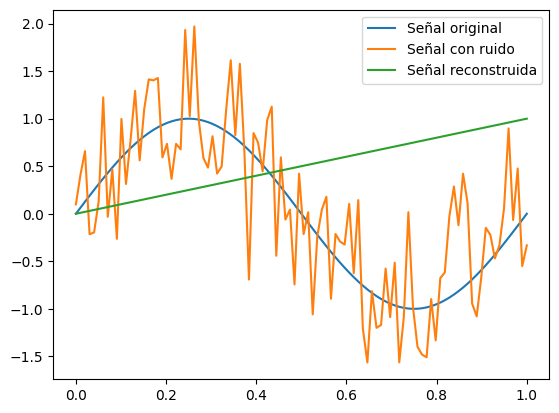

In [13]:
plt.plot(x,y,label = "Señal original")
plt.plot(x,t,label = "Señal con ruido")
plt.plot(x,phi@W,label = "Señal reconstruida")
plt.legend()
plt.show()

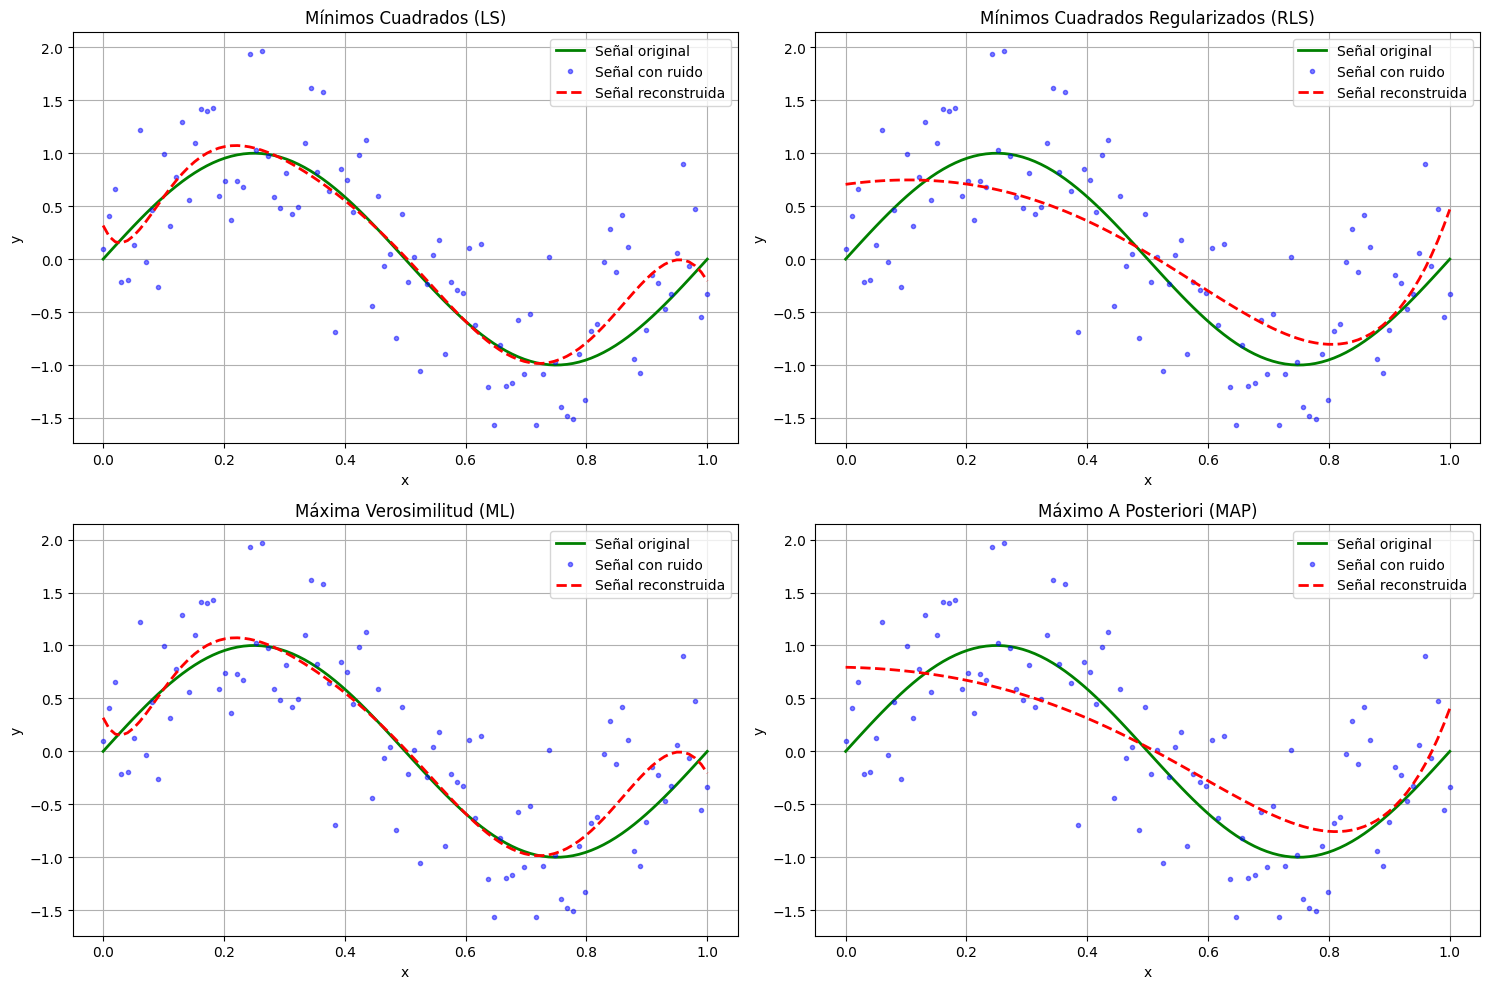

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Definimos los parámetros de regularización (l) para cada método
# 1. Least Squares (LS): Sin regularización
l_ls = 0.0
W_ls = solver(phi, t, l_ls)

# 2. Regularized Least Squares (RLS): Con regularización pequeña
l_rls = 0.1
W_rls = solver(phi, t, l_rls)

# 3. Maximum Likelihood (ML): Equivalente a LS (l = 0)
l_ml = 0.0
W_ml = solver(phi, t, l_ml)

# 4. Maximum A Posteriori (MAP): lambda es la relación entre las varianzas
# l_map = (varianza del ruido / varianza de los pesos) -> sigma_n^2 / sigma_w^2
sigma_n_cuadrado = sigma2 # Varianza del ruido estimada
sigma_w_cuadrado = 1.0    # Asumimos una varianza del prior para los pesos
l_map = sigma_n_cuadrado / sigma_w_cuadrado
W_map = solver(phi, t, l_map)

# Graficamos cada método en subplots para poder compararlos claramente
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

methods = [
    ("Mínimos Cuadrados (LS)", W_ls, axs[0, 0]),
    ("Mínimos Cuadrados Regularizados (RLS)", W_rls, axs[0, 1]),
    ("Máxima Verosimilitud (ML)", W_ml, axs[1, 0]),
    ("Máximo A Posteriori (MAP)", W_map, axs[1, 1])
]

for name, W_est, ax in methods:
    ax.plot(x, y, 'g-', label="Señal original", linewidth=2)
    ax.plot(x, t, 'b.', alpha=0.5, label="Señal con ruido")
    ax.plot(x, phi @ W_est, 'r--', label="Señal reconstruida", linewidth=2)
    ax.set_title(name)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()